# Spot F: integral against pulse height, channel by channel (-82 V, DCRC1pB trigger)

*Eleventh notebook of `relcal`. Draft prepared with Claude Code for A. Villano, 2026-11-01.*

The other way round from `integral-vs-height.ipynb`, where a band of Side2pF was cut in the plane of integral and height and then placed on the face: here the events are first cut on their **position**, the tight circle around the high-activity spot over the centre disc `F` (within `TIGHT_F` = 0.5 us of its centre in the plane of the 20 % delays, about 95 % spot events; see `spot-f-tight-energy.ipynb`), and then drawn in the plane of integral and height for all six channels. For comparison, the events outside both spots (farther than 2.25 us from either centre), with the same selection.

The selection is that of the position notebooks (`spots_82v.load()`): real triggers, the sum of the positive offset-subtracted integrals above 2, all six 20 % times present and within 60 us of each other. The height is `current_max` of `peak` (ADC counts above the baseline, `amps_per_adc` = 1), the integral that of `integral` (ADC counts x s); both use the baseline of samples 10 to 500. The dotted lines are each channel's saturated height (the 99.99th percentile of the height of all real triggers) and the largest integral it allows (that height times the 2.88 ms from the trigger to the end of the trace).

Needs `goldpan` and the output of `r76-82v-dcrc1pb.dataset.toml` in `~/goldsluice-output/r76-82v-dcrc1pb`. Run with the `darkmatter_cli_env` kernel.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors

from goldpan.adapters import parquet
from spots_82v import LETTERS, OUT, SPOTS, TIGHT_F, in_spot, load

d = load()
q = parquet.read(OUT, detector="NAI-S2").quantities
I = {k: d["integral"][:, n] for n, k in enumerate(LETTERS)}
H = {k: np.asarray(q[f"Side2p{k}"]["current_max"], dtype=float) for k in LETTERS}
real = d["trigger"] == "Unknown"
T_AFTER = (4096 - 500) * 0.8e-6
H_SAT = {k: np.percentile(H[k][real], 99.99) for k in LETTERS}

x0, y0, _ = SPOTS["F"]
spot = d["use"] & (np.hypot(d["xdel"] - x0, d["ydel"] - y0) < TIGHT_F)
outside = d["use"] & ~in_spot(d["xdel"], d["ydel"], "C", scale=1.5) & ~in_spot(d["xdel"], d["ydel"], "F", scale=1.5)
print(f"spot F (tight, {TIGHT_F} us): {spot.sum():,} events; outside both spots: {outside.sum():,} events")
print(f"{'':30}" + "".join(f"{'Side2p' + k:>10}" for k in LETTERS))
for name, m in (("spot F: median height", spot), ("outside: median height", outside)):
    print(f"{name:30}" + "".join(f"{np.median(H[k][m]):>10.0f}" for k in LETTERS))
for name, m in (("spot F: median integral", spot), ("outside: median integral", outside)):
    print(f"{name:30}" + "".join(f"{np.median(I[k][m]):>10.2f}" for k in LETTERS))
for name, m in (("spot F: median integral/height", spot), ("outside: median integral/height", outside)):
    print(f"{name:30}" + "".join(f"{np.median(I[k][m & (H[k] > 50)] / H[k][m & (H[k] > 50)]) * 1e3:>9.2f}m" for k in LETTERS))

spot F (tight, 0.5 us): 15,792 events; outside both spots: 313,494 events
                                 Side2pA   Side2pB   Side2pC   Side2pD   Side2pE   Side2pF
spot F: median height               1082       891       410       738       486       660
outside: median height              1096       901       417       739       497       676
spot F: median integral             2.50      2.21      1.05      1.88      1.24      1.71
outside: median integral            1.72      1.53      0.78      1.35      0.96      1.23
spot F: median integral/height     2.40m     2.57m     2.59m     2.58m     2.61m     2.65m


outside: median integral/height     1.69m     1.88m     2.09m     2.04m     2.17m     2.05m


## Integral against height, spot F

One panel per channel, on the same axes as in `integral-vs-height.ipynb`.

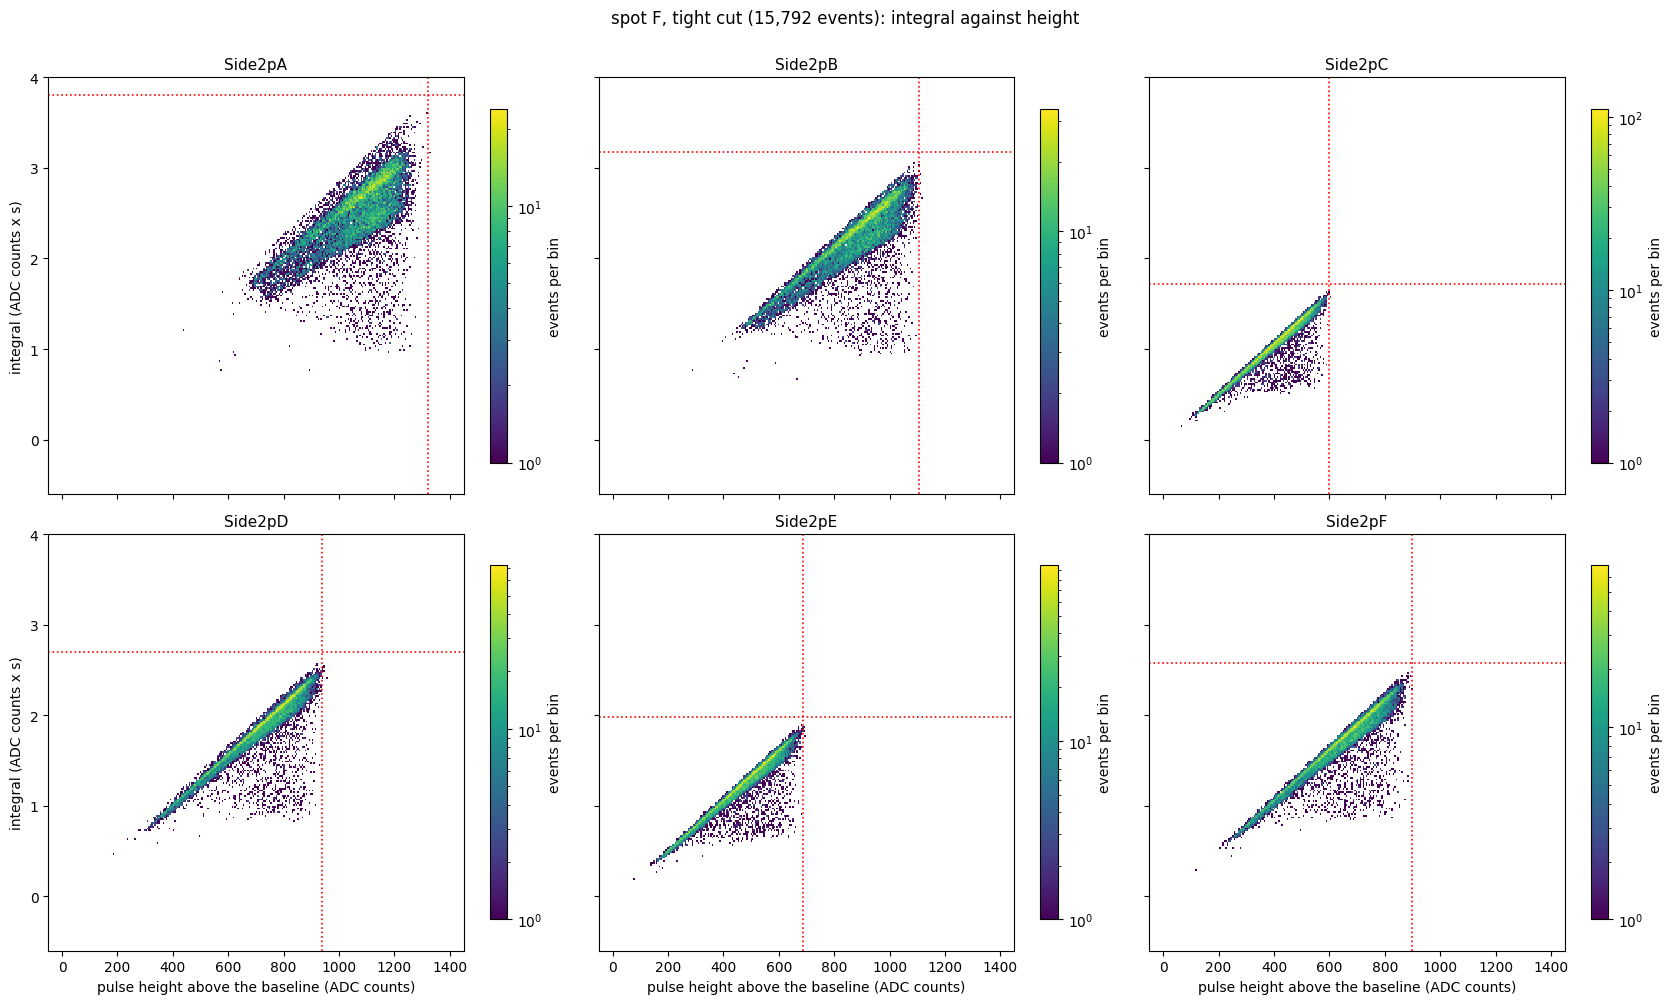

In [2]:
HR, IR = (-50, 1450), (-0.6, 4.0)

def six_panels(m, title, cmap="viridis"):
    fig, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True, sharey=True)
    for ax, k in zip(axes.flat, LETTERS):
        h = ax.hist2d(H[k][m], I[k][m], bins=[290, 230], range=[HR, IR], cmap=cmap, norm=colors.LogNorm(), cmin=1)
        ax.axvline(H_SAT[k], color="r", linestyle=":", linewidth=1.2)
        ax.axhline(H_SAT[k] * T_AFTER, color="r", linestyle=":", linewidth=1.2)
        ax.set_title(f"Side2p{k}", fontsize=11)
        fig.colorbar(h[3], ax=ax, shrink=0.85, label="events per bin")
    for ax in axes[-1]:
        ax.set_xlabel("pulse height above the baseline (ADC counts)")
    for ax in axes[:, 0]:
        ax.set_ylabel("integral (ADC counts x s)")
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    plt.show()

six_panels(spot, f"spot F, tight cut ({spot.sum():,} events): integral against height")

## The same, outside both spots

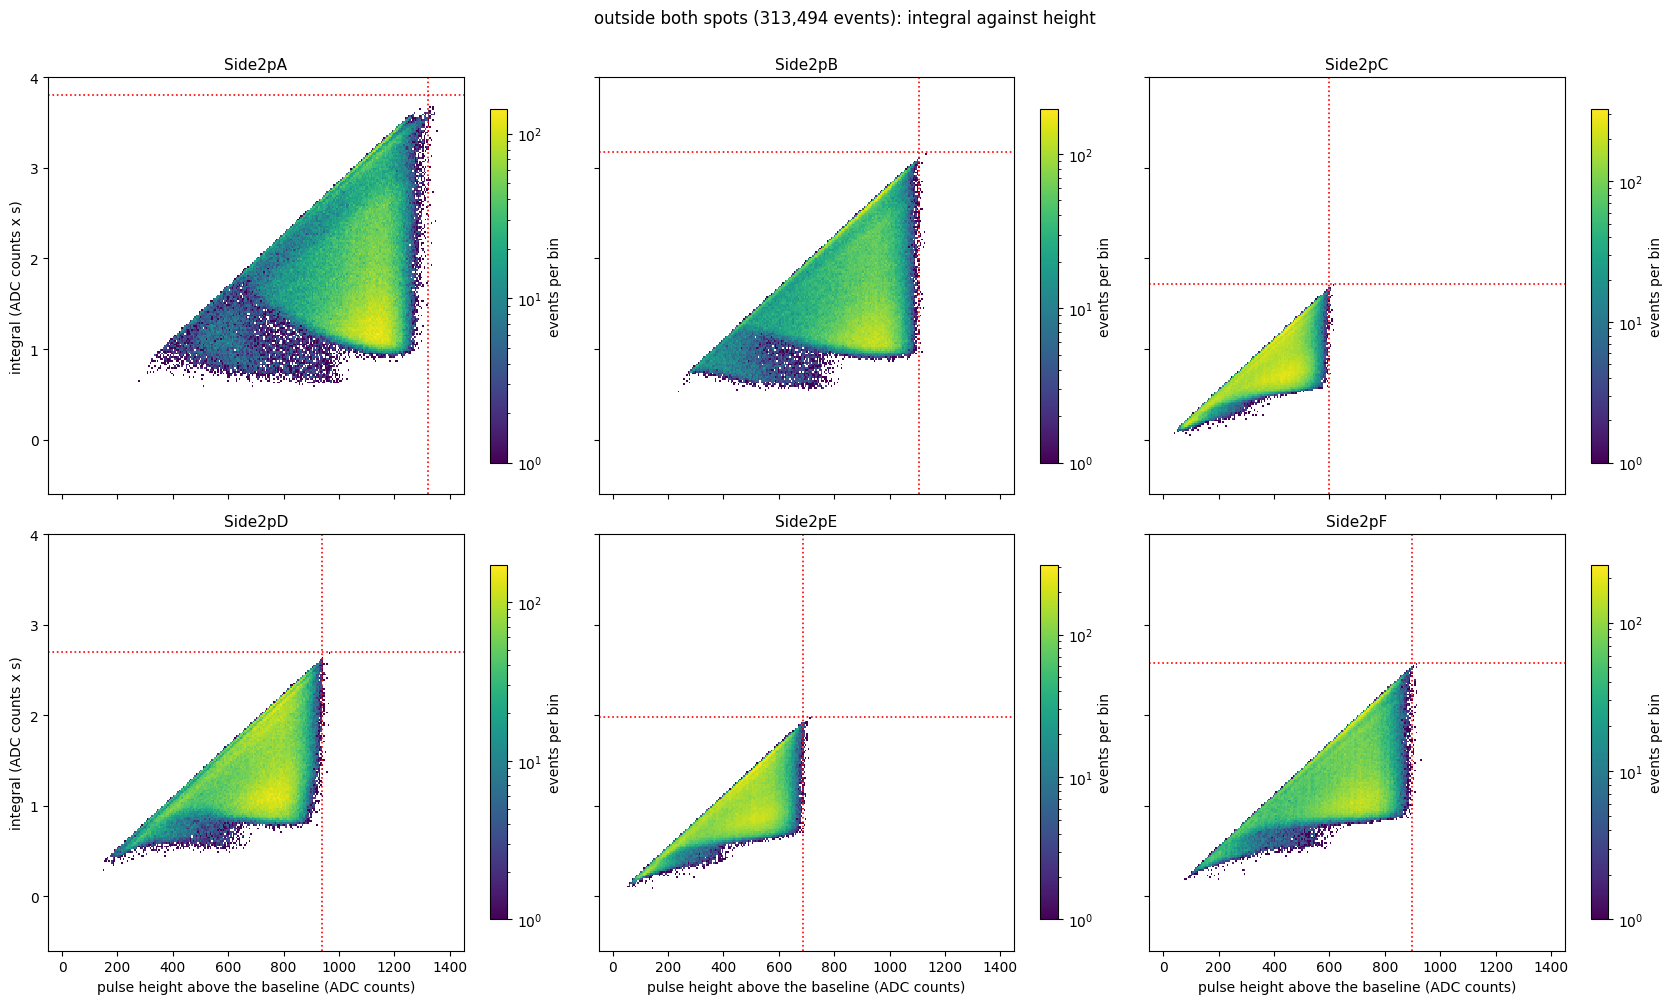

In [3]:
six_panels(outside, f"outside both spots ({outside.sum():,} events): integral against height")

## Effective pulse length

`integral / height` (ms) of each channel, spot F against the events outside the spots, each normalised to its number of events; for heights above 50 counts. A pulse of fixed shape has a fixed ratio; a saturated pulse held to the end of the trace reaches 2.88 ms (dotted).

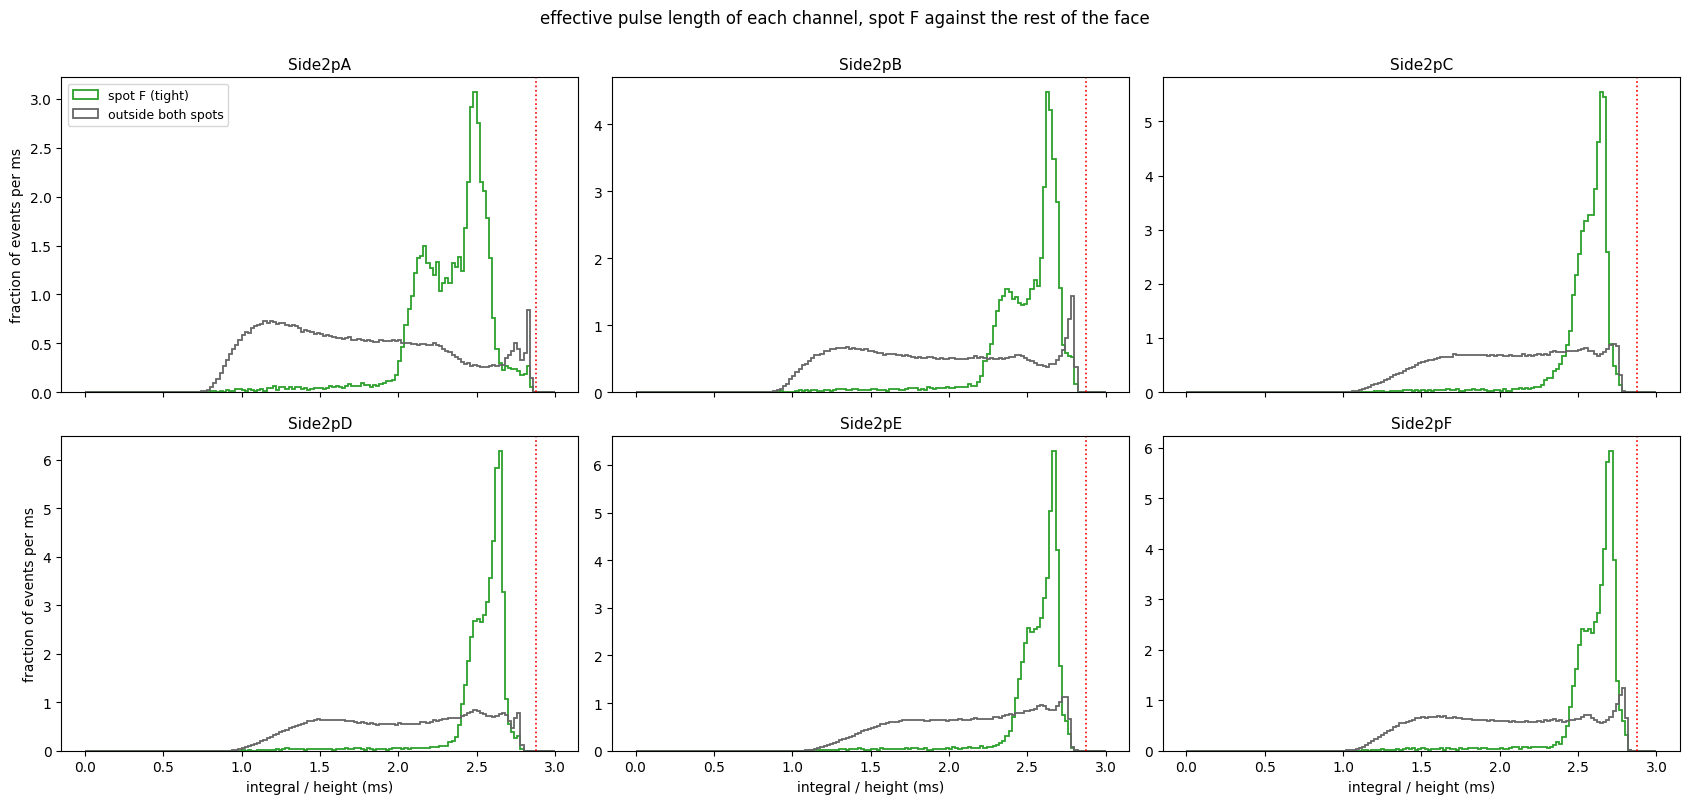

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
bins = np.linspace(0, 3, 151)
for ax, k in zip(axes.flat, LETTERS):
    for m, c, lab in ((spot, "C2", "spot F (tight)"), (outside, "0.4", "outside both spots")):
        mm = m & (H[k] > 50)
        ax.hist(I[k][mm] / H[k][mm] * 1e3, bins=bins, histtype="step", density=True, color=c, linewidth=1.3, label=lab)
    ax.axvline(T_AFTER * 1e3, color="r", linestyle=":", linewidth=1.2)
    ax.set_title(f"Side2p{k}", fontsize=11)
for ax in axes[-1]:
    ax.set_xlabel("integral / height (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("fraction of events per ms")
axes[0, 0].legend(fontsize=9)
fig.suptitle("effective pulse length of each channel, spot F against the rest of the face", y=1.0)
fig.tight_layout()
plt.show()

**Not done.** The spot's own pulse shapes are in `spot-f-tight-traces.ipynb`; this notebook only places its events in the plane of integral and height. About 5 % of the tight cut are ordinary events of that place of the face, not subtracted here.